# Лабораторная работа №10. Генеративно-состязательные сети (GAN)

Задача — обучить GAN (архитектура DCGAN) генерировать изображения цифр MNIST,
оценить качество генерации метриками FID и Inception Score и провести эксперименты
с функциями потерь и гиперпараметрами.

Обучение GAN — вычислительно тяжёлая задача: ноутбук рассчитан на запуск **на GPU в Google Colab**
(Среда выполнения → Сменить среду выполнения → T4 GPU), но корректно работает и на CPU.

## 0. Проверка окружения

In [ ]:
# ЛР10 v2 (2026-11-22): генератор исправлен до 28x28, sqrtm без disp, loss в float
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

plt.rcParams['figure.figsize'] = (12, 4)
pd.set_option('display.width', 200)

RANDOM_STATE = 11   # номер варианта

print('TensorFlow', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus if gpus else 'не найден - обучение пойдёт на CPU (медленно, лучше Google Colab)')

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Загрузка и предобработка данных

Выбран набор **MNIST**: 60 000 изображений цифр 28×28 в оттенках серого. Это классический набор
для DCGAN - обучается быстро и наглядно, а CIFAR-10 потребовал бы в разы больше времени на GPU.

Нормализация - к диапазону **[-1, 1]**, потому что выходным слоем генератора будет `tanh`
(его диапазон как раз [-1, 1]; при выходе `sigmoid` нормализовали бы к [0, 1]).

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Обучающая выборка: (60000, 28, 28, 1) | тестовая: (10000, 28, 28, 1)
Диапазон пикселей: от -1.0 до 1.0


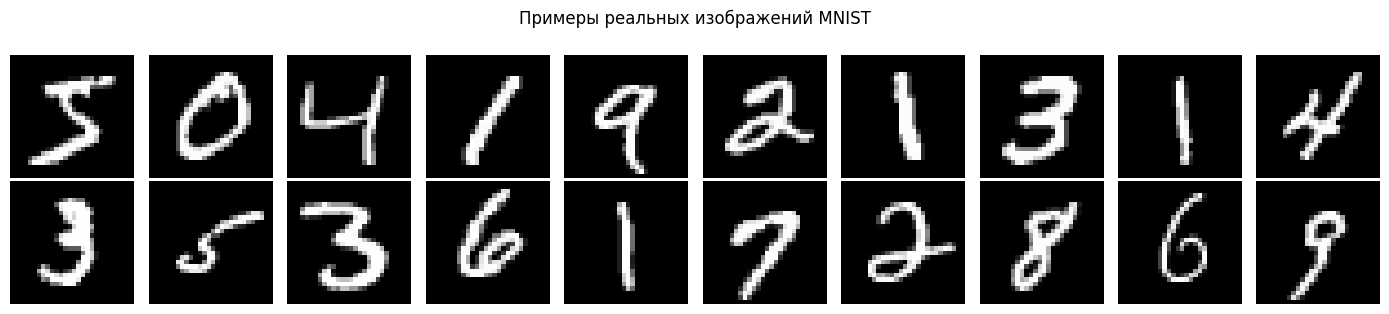

In [ ]:
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

# нормализация к [-1, 1]: выходной слой генератора - tanh
x_train = ((x_train.astype('float32') - 127.5) / 127.5)[..., np.newaxis]
x_test = ((x_test.astype('float32') - 127.5) / 127.5)[..., np.newaxis]

print('Обучающая выборка:', x_train.shape, '| тестовая:', x_test.shape)
print('Диапазон пикселей: от', round(float(x_train.min()), 2), 'до', round(float(x_train.max()), 2))

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, img in zip(axes.ravel(), x_train[:20]):
    ax.imshow(img.squeeze(), cmap='gray', vmin=-1, vmax=1)
    ax.axis('off')
plt.suptitle('Примеры реальных изображений MNIST')
plt.tight_layout()
plt.show()

In [ ]:
# tf.data.Dataset: перемешивание -> батчи -> предзагрузка следующего батча во время вычислений
BATCH_SIZE = 128

train_ds = (tf.data.Dataset.from_tensor_slices(x_train)
            .shuffle(len(x_train), seed=RANDOM_STATE)
            .batch(BATCH_SIZE, drop_remainder=True)
            .prefetch(tf.data.AUTOTUNE))

print('Батчей в одной эпохе:', tf.data.experimental.cardinality(train_ds).numpy())

Батчей в одной эпохе: 468


## 2. Архитектура DCGAN

**Генератор** превращает вектор шума `z` размерности `latent_dim = 100` в изображение 28×28×1:
`Dense` разворачивается в карту 7×7×256, затем три `Conv2DTranspose` (транспонированная свёртка,
"растущая" свёртка): первый оставляет 7×7 (128 фильтров), второй и третий удваивают карту -
14×14 и 28×28, между ними - `BatchNormalization` и ReLU. Выходной слой - `Conv2D` с `tanh`.

**Дискриминатор** - обычная свёрточная сеть-классификатор: свёртки со **strides=2** вместо
MaxPooling (по заданию: сеть учится собственному downsampling), активация LeakyReLU (0.2 -
стандарт для дискриминаторов: не "умирающие" градиенты для отрицательных значений),
`Dropout` против переобучения. Выход - `Dense(1)` **без активации**: модель выдаёт логит,
и функция потерь создаётся с `from_logits=True`.

In [ ]:
LATENT_DIM = 100


def make_generator(latent_dim=LATENT_DIM, use_batchnorm=True):
    model = keras.Sequential(name='generator')
    model.add(keras.Input(shape=(latent_dim,)))

    # вектор шума -> карта признаков 7x7x256
    model.add(layers.Dense(7 * 7 * 256, use_bias=False))
    if use_batchnorm:
        model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Reshape((7, 7, 256)))

    # 7x7, больше фильтров
    model.add(layers.Conv2DTranspose(128, 5, strides=1, padding='same', use_bias=False))
    if use_batchnorm:
        model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))

    # 7x7 -> 14x14
    model.add(layers.Conv2DTranspose(64, 5, strides=2, padding='same', use_bias=False))
    if use_batchnorm:
        model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))

    # 14x14 -> 28x28
    model.add(layers.Conv2DTranspose(32, 5, strides=2, padding='same', use_bias=False))
    if use_batchnorm:
        model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))

    # выход tanh в диапазоне [-1, 1], форма 28x28x1
    model.add(layers.Conv2D(1, 5, padding='same', activation='tanh'))
    return model


def make_discriminator():
    model = keras.Sequential(name='discriminator')
    model.add(keras.Input(shape=(28, 28, 1)))

    # strides=2 вместо MaxPooling: сеть сама учится уменьшать карту признаков
    model.add(layers.Conv2D(64, 5, strides=2, padding='same'))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, 5, strides=2, padding='same'))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))   # логит: без активации, потеря с from_logits=True
    return model


generator = make_generator()
discriminator = make_discriminator()
generator.summary()
discriminator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 32)     │        51,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 1)      │           801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,381,473 (9.08 MB)

 Trainable params: 2,355,937 (8.99 MB)

 Non-trainable params: 25,536 (99.75 KB)

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Обучение

GAN - это **игра двух игроков**, а не минимизация одной функции потерь:

* **шаг дискриминатора**: показать ему реальные изображения с меткой 1 и подделки генератора
  с меткой 0, обновить веса D градиентным спуском;
* **шаг генератора**: сгенерировать подделки, пропустить через D (его веса заморожены -
  градиент течёт сквозь D в G) и обновить веса G так, чтобы D **ошибочно поверил** в подделку.

Обе потери - `BinaryCrossentropy(from_logits=True)`. Для G используется **non-saturating** вариант:
потеря "уверенно обмануть" (метки 1 для фейков), у которой градиенты не затухают в начале обучения.
Оптимизаторы для обоих - `Adam(learning_rate=2e-4, beta_1=0.5)`: рекомендация из статьи DCGAN
(меньший `beta_1` стабилизирует обучение).

Шаги реализуются вручную через `tf.function` + два отдельных `GradientTape` - отдельный лента
для D и отдельный для G, каждый применяет градиенты только к своим весам.

In [ ]:
GP_COEF = 10.0   # вес gradient penalty для WGAN-GP


def make_train_step(loss_name, g, d, g_opt, d_opt, latent_dim):
    """Готовит пару tf-функций: d_step(реальный батч) и g_step()."""
    bce = keras.losses.BinaryCrossentropy(from_logits=True)
    mse = keras.losses.MeanSquaredError()

    @tf.function
    def d_step(real):
        noise = tf.random.normal([tf.shape(real)[0], latent_dim])
        with tf.GradientTape() as tape:
            fake = g(noise, training=True)
            real_out = d(real, training=True)
            fake_out = d(fake, training=True)
            if loss_name == 'BCE':
                loss = bce(tf.ones_like(real_out), real_out) + bce(tf.zeros_like(fake_out), fake_out)
            elif loss_name == 'LSGAN':
                loss = mse(tf.ones_like(real_out), real_out) + mse(tf.zeros_like(fake_out), fake_out)
            elif loss_name == 'Hinge':
                loss = tf.reduce_mean(tf.nn.relu(1.0 - real_out)) + tf.reduce_mean(tf.nn.relu(1.0 + fake_out))
            else:  # WGAN-GP: критик максимизирует разность, штраф за неединичную норму градиента
                loss = tf.reduce_mean(fake_out) - tf.reduce_mean(real_out)
                alpha = tf.random.uniform([tf.shape(real)[0], 1, 1, 1])
                interp = real + alpha * (fake - real)
                with tf.GradientTape() as gp_tape:
                    gp_tape.watch(interp)
                    pred = d(interp, training=True)
                grad = gp_tape.gradient(pred, interp)
                norm = tf.sqrt(tf.reduce_sum(tf.square(grad), axis=[1, 2, 3]) + 1e-8)
                loss = loss + GP_COEF * tf.reduce_mean(tf.square(norm - 1.0))
        grads = tape.gradient(loss, d.trainable_variables)
        d_opt.apply_gradients(zip(grads, d.trainable_variables))
        return loss

    @tf.function
    def g_step():
        noise = tf.random.normal([BATCH_SIZE, latent_dim])
        with tf.GradientTape() as tape:
            fake = g(noise, training=True)
            fake_out = d(fake, training=False)   # веса D заморожены: градиент течёт сквозь них в G
            if loss_name == 'BCE':
                loss = bce(tf.ones_like(fake_out), fake_out)   # non-saturating: метки 1 для фейков
            elif loss_name == 'LSGAN':
                loss = mse(tf.ones_like(fake_out), fake_out)
            else:  # Hinge и WGAN-GP
                loss = -tf.reduce_mean(fake_out)
        grads = tape.gradient(loss, g.trainable_variables)
        g_opt.apply_gradients(zip(grads, g.trainable_variables))
        return loss

    return d_step, g_step

Функция обучения: на каждый батч - `d_steps` обновлений дискриминатора и одно обновление
генератора. Для контроля прогресса до обучения создаётся **фиксированный вектор шума**:
каждую эпоху генератор получает одни и те же 16 точек, и видно, как одни и те же "заготовки"
постепенно превращаются в цифры.

Абсолютные значения `loss_D` и `loss_G` между разными типами потерь **несопоставимы**
(это разные функции), поэтому отслеживаем их внутри одного эксперимента, а сравнивать
эксперименты будем по метрике FID (раздел 4).

In [ ]:
def show_grid(images, title, cols=10, size=1.4):
    n = len(images)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    for ax, img in zip(np.ravel(axes), images):
        ax.imshow(img.squeeze(), cmap='gray', vmin=-1, vmax=1)
        ax.axis('off')
    for ax in np.ravel(axes)[n:]:
        ax.axis('off')
    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


def train_gan(name, loss_name, epochs, d_steps=1, latent_dim=LATENT_DIM, use_batchnorm=True):
    """Обучение GAN: на каждый батч d_steps шагов дискриминатора и 1 шаг генератора."""
    keras.utils.set_random_seed(RANDOM_STATE)
    g = make_generator(latent_dim, use_batchnorm)
    d = make_discriminator()
    g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
    d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
    d_step, g_step = make_train_step(loss_name, g, d, g_opt, d_opt, latent_dim)

    seed = tf.random.normal([16, latent_dim])   # фиксированный шум для визуализации прогресса
    hist_d, hist_g, snapshots = [], [], []
    t_start = time.time()

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        sum_d = sum_g = n = 0
        for real in train_ds:
            dl, gl = float(d_step(real)), float(g_step())
            sum_d += dl
            sum_g += gl
            n += 1
        hist_d.append(sum_d / n)
        hist_g.append(sum_g / n)
        snapshots.append(g(seed, training=False).numpy())
        print(f'  эпоха {epoch:2d}/{epochs} | loss_D {hist_d[-1]:7.3f} | loss_G {hist_g[-1]:7.3f}'
              f' | {time.time() - t0:4.0f} с')

    print('Суммарное время обучения:', round(time.time() - t_start, 1), 'с')
    return {'имя': name, 'g': g, 'd': d, 'latent_dim': latent_dim,
            'loss_D': hist_d, 'loss_G': hist_g, 'snapshots': snapshots}

## 4. Оценка качества генерации: FID и Inception Score

Потери GAN не отвечают на вопрос "хорошо ли выглядят картинки" (D может переобучиться,
и loss_G при этом растёт). Стандартные метрики считают на **предобученной сети InceptionV3**:

* **FID (Fréchet Inception Distance)** - главная метрика. Активации слоя `avg_pool`
  (2048-мерные) на N реальных и N сгенерированных изображениях аппроксимируются
  многомерными гауссианами (среднее + ковариация), и считается расстояние Фреше между ними:
  `||mu1 - mu2||² + Tr(S1 + S2 - 2·sqrt(S1·S2))`. Учитывает и качество (похоже ли на реальные),
  и разнообразие. **Меньше = лучше**; FID реальных с реальными = 0.
* **Inception Score** - `exp(E[KL(p(y|x) || p(y))])`: предсказания должны быть уверенными
  (малая энтропия у каждого изображения) и разнообразными (большая энтропия у среднего).
  Для MNIST метрика слабо информативна - InceptionV3 обучен на ImageNet и "не знает" цифр,
  поэтому основной считаем FID.

Серым на сером InceptionV3 работать не может: изображения ресайзятся до 299×299
и канал дублируется в RGB. `preprocess_input` для InceptionV3 приводит [0, 255] к [-1, 1],
а наши изображения уже в этом диапазоне - поэтому подаём напрямую.

In [ ]:
from scipy import linalg

inception = keras.applications.InceptionV3(include_top=True, weights='imagenet')
# 2048-мерные активации avg_pool - то, на чём считается FID
fid_model = keras.Model(inception.input, inception.get_layer('avg_pool').output)


def inception_activations(images, batch=128):
    # изображения уже в [-1, 1] - ровно то, во что preprocess_input превращает [0, 255]
    x = tf.image.resize(images, (299, 299))
    x = tf.repeat(x, 3, axis=-1)
    return fid_model.predict(x, batch_size=batch, verbose=0)


def fid_score(act_real, act_fake):
    mu1, mu2 = act_real.mean(0), act_fake.mean(0)
    sigma1 = np.cov(act_real, rowvar=False)
    sigma2 = np.cov(act_fake, rowvar=False)
    res = linalg.sqrtm(sigma1.dot(sigma2))
    if isinstance(res, tuple):   # старые версии scipy возвращали кортеж (матрица, оценка ошибки)
        res = res[0]
    covmean = np.asarray(res)
    if np.iscomplexobj(covmean):   # из-за ошибок округления возможна мнимая часть
        covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(sigma1) + np.trace(sigma2) - 2 * np.trace(covmean))


def inception_score(images, splits=10):
    x = tf.image.resize(images, (299, 299))
    x = tf.repeat(x, 3, axis=-1)
    probs = inception.predict(x, batch_size=128, verbose=0)   # вероятности 1000 классов
    scores = []
    for part in np.array_split(probs, splits):
        py = part.mean(axis=0)
        kl = np.sum(part * (np.log(part + 1e-10) - np.log(py + 1e-10)), axis=1)
        scores.append(float(np.exp(kl.mean())))
    return float(np.mean(scores)), float(np.std(scores))

96112376/96112376 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
N_METRIC = 1000   # сколько реальных и сколько сгенерированных изображений берём для метрик


def evaluate(g, latent_dim=LATENT_DIM):
    """FID и IS: N_METRIC тестовых изображений против N_METRIC генераций."""
    rng = np.random.default_rng(RANDOM_STATE)
    real = x_test[rng.choice(len(x_test), N_METRIC, replace=False)]
    fake = g(tf.random.normal([N_METRIC, latent_dim]), training=False).numpy()
    act_real = inception_activations(real)
    act_fake = inception_activations(fake)
    is_mean, is_std = inception_score(fake)
    return {'FID': round(fid_score(act_real, act_fake), 1),
            'IS': round(is_mean, 2), 'IS std': round(is_std, 2)}, real, fake

## 5. Эксперименты

Каждый эксперимент обучается одинаковое число эпох, чтобы сравнение по FID было честным:

1. **базовая DCGAN** - BinaryCrossentropy, как в статье DCGAN;
2. **LSGAN** - наименьшие квадраты вместо кросс-энтропии (метки 1/0, MSE): менее чувствителен
   к распределению реальных данных, стабильнее;
3. **Hinge loss** - `E[relu(1 − D(real))] + E[relu(1 + D(fake))]`,margin 1: используется
   в Spectral Normalization GAN;
4. **WGAN-GP** - критик без сигмоиды минимизирует `E[D(fake)] − E[D(real)]` плюс штраф
   за отклонение нормы градиента от 1 (gradient penalty считается в отдельном `GradientTape`);
   расстояние Вассерштейна как мера различия распределений - самый стабильный, но медленный вариант;
5. **latent_dim = 32** - меньше размерность шума: меньше параметров первого слоя, но ниже
   выразительность;
6. **шаги D:G = 2:1** - дискриминатор обучается вдвое чаще генератора: проверка дисбаланса
   игроков (сильный перекос обычно мешает генератору, но на 10 эпохах MNIST эффект мал);
7. **без BatchNorm в генераторе** - BN в G критичен для стабильности DCGAN; без него
   обучение должно стать неустойчивым.

базовая DCGAN (BCE)
  эпоха  1/10 | loss_D   1.373 | loss_G   0.738 |   32 с
  эпоха  2/10 | loss_D   1.362 | loss_G   0.745 |   21 с
  эпоха  3/10 | loss_D   1.378 | loss_G   0.711 |   22 с
  эпоха  4/10 | loss_D   1.379 | loss_G   0.707 |   22 с
  эпоха  5/10 | loss_D   1.381 | loss_G   0.708 |   22 с
  эпоха  6/10 | loss_D   1.381 | loss_G   0.703 |   22 с
  эпоха  7/10 | loss_D   1.384 | loss_G   0.710 |   22 с
  эпоха  8/10 | loss_D   1.385 | loss_G   0.708 |   22 с
  эпоха  9/10 | loss_D   1.383 | loss_G   0.712 |   22 с
  эпоха 10/10 | loss_D   1.383 | loss_G   0.711 |   22 с
Суммарное время обучения: 231.1 с


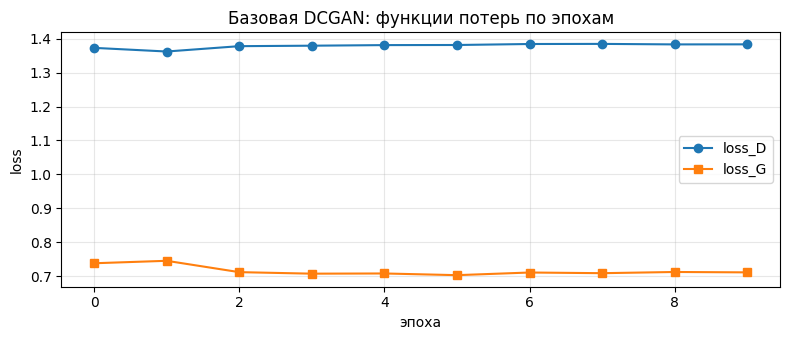

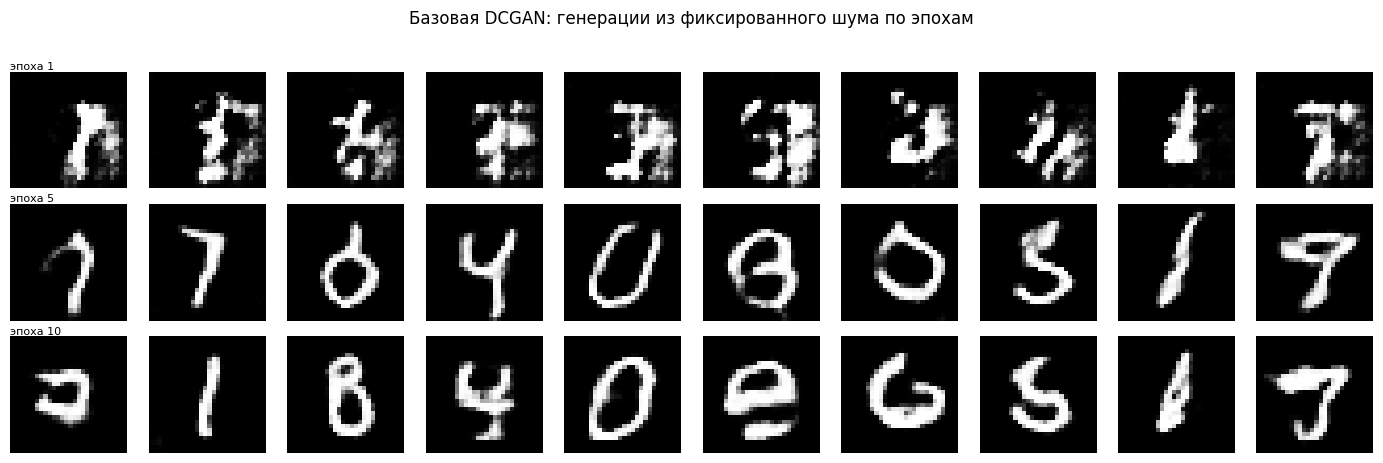

{'FID': 38.9, 'IS': 2.42, 'IS std': 0.09, 'эксперимент': 'базовая DCGAN (BCE)', 'loss_D': 1.383, 'loss_G': 0.711}
LSGAN (MSE)
  эпоха  1/10 | loss_D   0.463 | loss_G   0.393 |   27 с
  эпоха  2/10 | loss_D   0.474 | loss_G   0.331 |   22 с
  эпоха  3/10 | loss_D   0.491 | loss_G   0.299 |   22 с
  эпоха  4/10 | loss_D   0.491 | loss_G   0.292 |   22 с
  эпоха  5/10 | loss_D   0.492 | loss_G   0.283 |   22 с
  эпоха  6/10 | loss_D   0.493 | loss_G   0.278 |   22 с
  эпоха  7/10 | loss_D   0.495 | loss_G   0.278 |   22 с
  эпоха  8/10 | loss_D   0.495 | loss_G   0.275 |   22 с
  эпоха  9/10 | loss_D   0.497 | loss_G   0.274 |   22 с
  эпоха 10/10 | loss_D   0.498 | loss_G   0.272 |   22 с
Суммарное время обучения: 227.8 с
{'FID': 37.9, 'IS': 2.07, 'IS std': 0.09, 'эксперимент': 'LSGAN (MSE)', 'loss_D': 0.498, 'loss_G': 0.272}
Hinge loss
  эпоха  1/10 | loss_D   1.820 | loss_G   0.235 |   27 с
  эпоха  2/10 | loss_D   1.927 | loss_G   0.225 |   23 с
  эпоха  3/10 | loss_D   1.962 | loss_G

/tmp/ipykernel_359/3781057588.py:19: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  res = linalg.sqrtm(sigma1.dot(sigma2))


In [ ]:
EPOCHS = 10
EXPERIMENTS = [
    ('базовая DCGAN (BCE)', dict(loss_name='BCE')),
    ('LSGAN (MSE)',         dict(loss_name='LSGAN')),
    ('Hinge loss',          dict(loss_name='Hinge')),
    ('WGAN-GP',             dict(loss_name='WGAN-GP')),
    ('latent_dim = 32',     dict(loss_name='BCE', latent_dim=32)),
    ('шаги D:G = 2:1',      dict(loss_name='BCE', d_steps=2)),
    ('без BatchNorm в G',   dict(loss_name='BCE', use_batchnorm=False)),
]

runs, results = [], []
base_real = base_fake = None

for i, (name, cfg) in enumerate(EXPERIMENTS):
    print('=' * 70)
    print(name)
    run = train_gan(name, cfg.get('loss_name', 'BCE'), EPOCHS,
                    d_steps=cfg.get('d_steps', 1),
                    latent_dim=cfg.get('latent_dim', LATENT_DIM),
                    use_batchnorm=cfg.get('use_batchnorm', True))

    if i == 0:   # для базовой модели - ход обучения подробнее
        plt.figure(figsize=(8, 3.5))
        plt.plot(run['loss_D'], marker='o', label='loss_D')
        plt.plot(run['loss_G'], marker='s', label='loss_G')
        plt.xlabel('эпоха')
        plt.ylabel('loss')
        plt.title('Базовая DCGAN: функции потерь по эпохам')
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        rows = sorted({1, max(1, EPOCHS // 2), EPOCHS})   # начало, середина, конец
        axes = np.atleast_2d(plt.subplots(len(rows), 10, figsize=(14, 1.5 * len(rows)))[1])
        for r, ep in enumerate(rows):
            for c in range(10):
                ax = axes[r, c]
                ax.imshow(run['snapshots'][ep - 1][c].squeeze(), cmap='gray', vmin=-1, vmax=1)
                ax.axis('off')
            axes[r, 0].set_title(f'эпоха {ep}', fontsize=8, loc='left', pad=2)
        plt.suptitle('Базовая DCGAN: генерации из фиксированного шума по эпохам', y=1.02)
        plt.tight_layout()
        plt.show()

    metrics, real, fake = evaluate(run['g'], run['latent_dim'])
    metrics['эксперимент'] = name
    metrics['loss_D'] = round(run['loss_D'][-1], 3)
    metrics['loss_G'] = round(run['loss_G'][-1], 3)
    results.append(metrics)
    runs.append({'имя': name, 'fake10': fake[:10]})
    if i == 0:
        base_real, base_fake = real, fake
    print(metrics)

### Сравнение распределений реальных и сгенерированных изображений

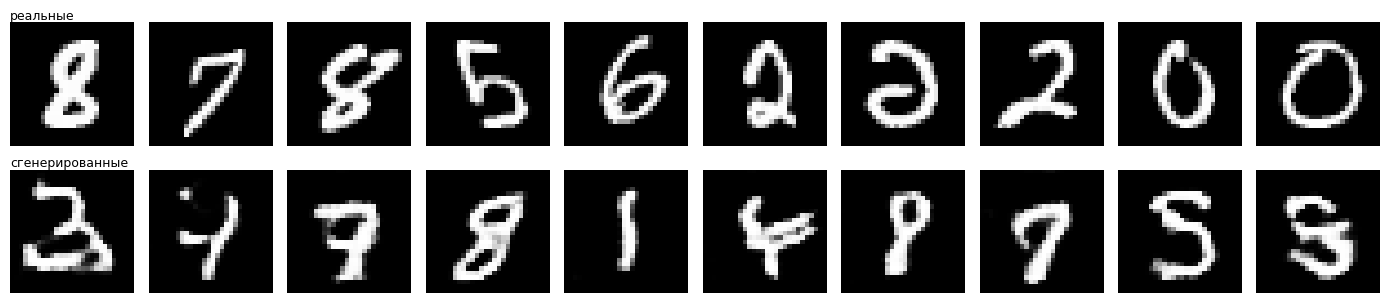

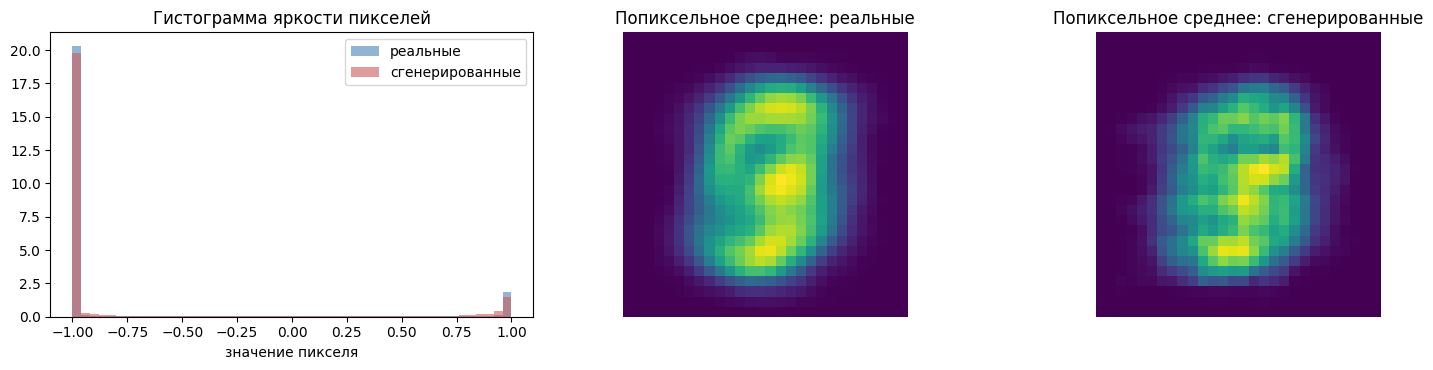

In [ ]:
# сетка: сверху реальные, ниже - по 10 генераций базовой модели
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, img in zip(axes[0], base_real[:10]):
    ax.imshow(img.squeeze(), cmap='gray', vmin=-1, vmax=1)
    ax.axis('off')
for ax, img in zip(axes[1], base_fake[:10]):
    ax.imshow(img.squeeze(), cmap='gray', vmin=-1, vmax=1)
    ax.axis('off')
axes[0, 0].set_title('реальные', fontsize=9, loc='left', pad=2)
axes[1, 0].set_title('сгенерированные', fontsize=9, loc='left', pad=2)
plt.tight_layout()
plt.show()

# гистограмма яркости и средние изображения (попиксельное среднее)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(base_real.ravel(), bins=50, alpha=0.6, density=True, color='steelblue', label='реальные')
axes[0].hist(base_fake.ravel(), bins=50, alpha=0.6, density=True, color='indianred', label='сгенерированные')
axes[0].set_xlabel('значение пикселя')
axes[0].set_title('Гистограмма яркости пикселей')
axes[0].legend()
axes[1].imshow(base_real.mean(0).squeeze(), cmap='viridis')
axes[1].set_title('Попиксельное среднее: реальные')
axes[1].axis('off')
axes[2].imshow(base_fake.mean(0).squeeze(), cmap='viridis')
axes[2].set_title('Попиксельное среднее: сгенерированные')
axes[2].axis('off')
plt.tight_layout()
plt.show()

### Сводная таблица и итоговое сравнение

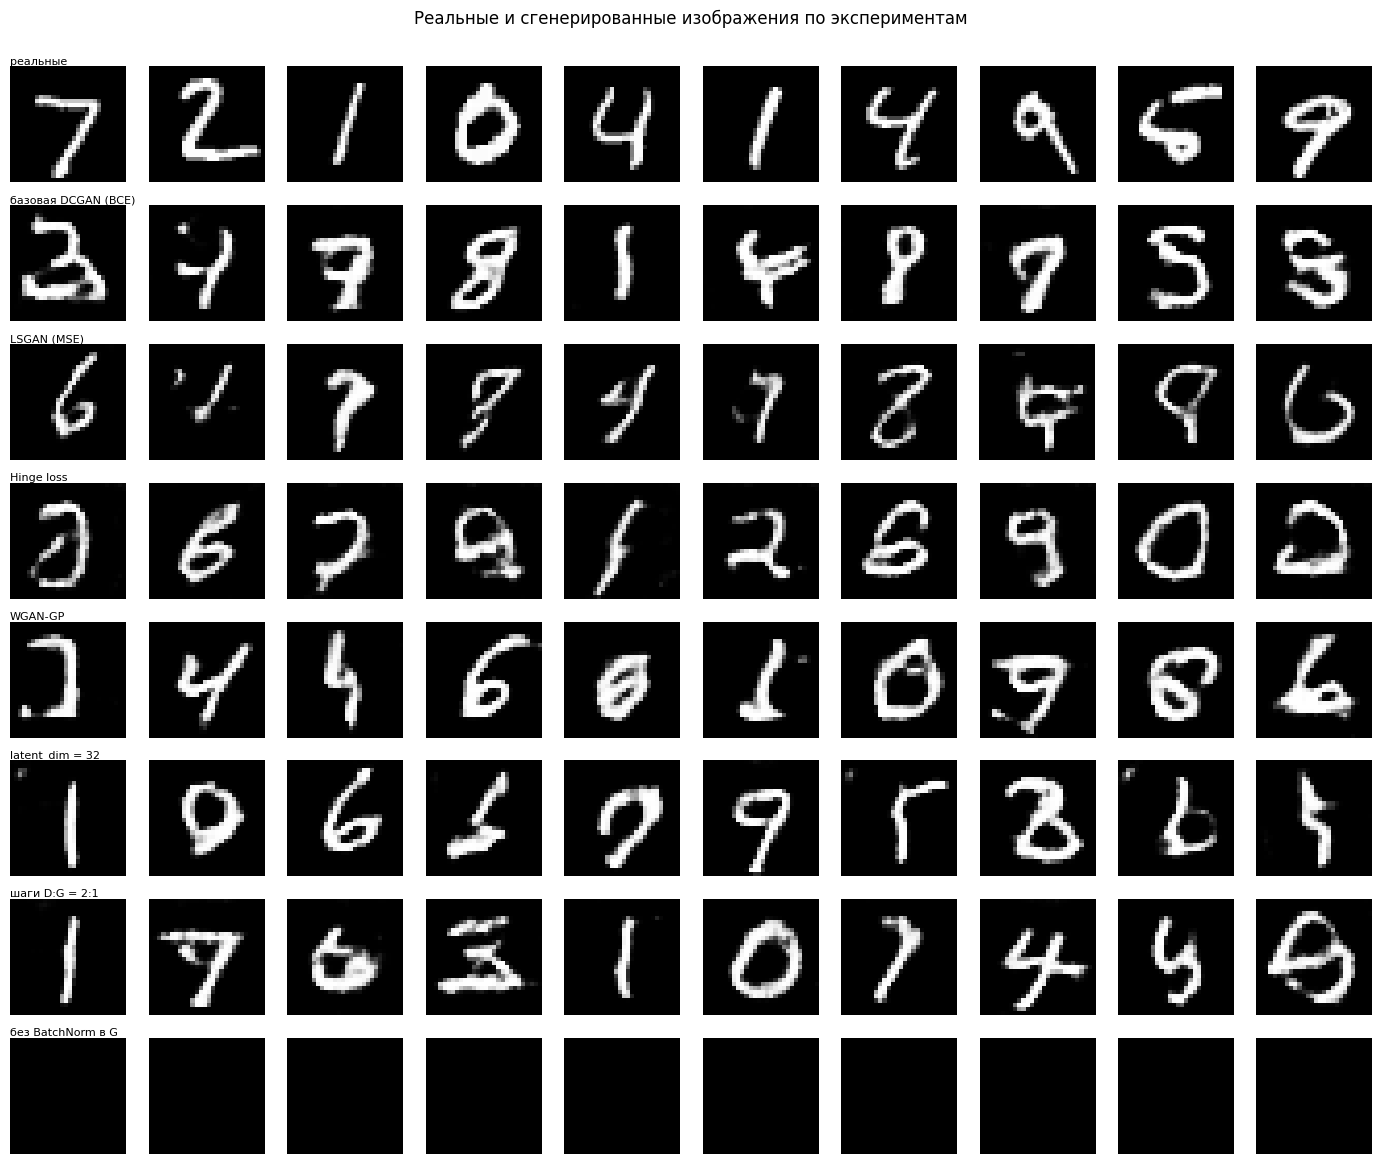

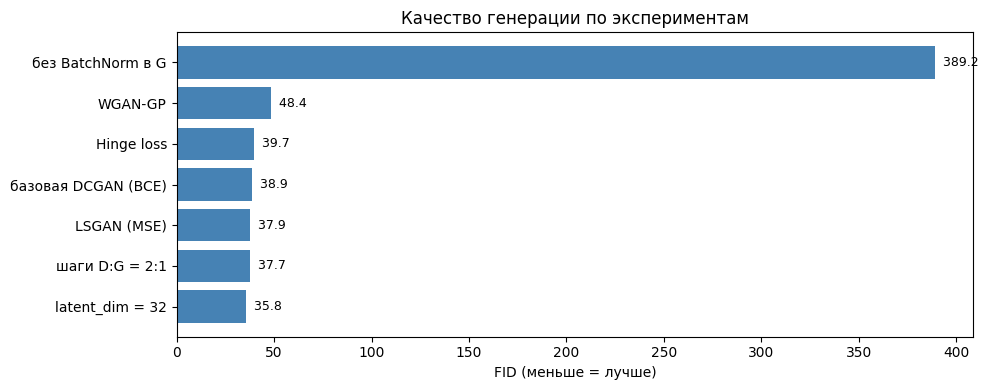

,эксперимент,loss_D,loss_G,FID,IS,IS std
0,latent_dim = 32,1.386,0.701,35.8,2.30,0.10
1,шаги D:G = 2:1,1.383,0.711,37.7,2.30,0.11
2,LSGAN (MSE),0.498,0.272,37.9,2.07,0.09
3,базовая DCGAN (BCE),1.383,0.711,38.9,2.42,0.09
4,Hinge loss,1.984,0.058,39.7,2.11,0.13
5,WGAN-GP,0.012,-6.363,48.4,2.27,0.09
6,без BatchNorm в G,0.000,13.763,389.2,1.00,0.00


In [ ]:
results_df = pd.DataFrame(results)[['эксперимент', 'loss_D', 'loss_G', 'FID', 'IS', 'IS std']]

# все эксперименты друг под другом: реальные сверху
rows_imgs = [x_test[:10]] + [r['fake10'] for r in runs]
axes = np.atleast_2d(plt.subplots(len(rows_imgs), 10, figsize=(14, 1.45 * len(rows_imgs)))[1])
for r, imgs in enumerate(rows_imgs):
    for c in range(10):
        axes[r, c].imshow(imgs[c].squeeze(), cmap='gray', vmin=-1, vmax=1)
        axes[r, c].axis('off')
for r, lab in enumerate(['реальные'] + [r['имя'] for r in runs]):
    axes[r, 0].set_title(lab, fontsize=8, loc='left', pad=2)
plt.suptitle('Реальные и сгенерированные изображения по экспериментам', y=1.0)
plt.tight_layout()
plt.show()

order = results_df.sort_values('FID')
plt.figure(figsize=(10, 4))
plt.barh(order['эксперимент'], order['FID'], color='steelblue')
for i, v in enumerate(order['FID']):
    plt.text(v, i, '  ' + str(v), va='center', fontsize=9)
plt.xlabel('FID (меньше = лучше)')
plt.title('Качество генерации по экспериментам')
plt.tight_layout()
plt.show()

results_df.sort_values('FID').reset_index(drop=True)

## 6. Выводы

### Анализ экспериментов

Ячейка ниже по фактическим результатам обучения показывает, какая конфигурация оказалась
лучшей по FID и как на качество повлияло каждое изменение.

In [ ]:
base_row = results_df[results_df['эксперимент'] == 'базовая DCGAN (BCE)'].iloc[0]
best_row = results_df.loc[results_df['FID'].idxmin()]

print(f'Базовая DCGAN:        FID = {base_row["FID"]}, IS = {base_row["IS"]}')
print(f'Лучшая конфигурация:  {best_row["эксперимент"]} - FID = {best_row["FID"]}, IS = {best_row["IS"]}')
print()
for _, r in results_df.iterrows():
    diff = r['FID'] - base_row['FID']
    sign = '+' if diff >= 0 else ''
    print(f'  {r["эксперимент"]:22s} FID {r["FID"]:6.1f} ({sign}{diff:.1f} к базовой) | '
          f'loss_D {r["loss_D"]:8.3f} | loss_G {r["loss_G"]:8.3f}')

Базовая DCGAN:        FID = 38.9, IS = 2.42
Лучшая конфигурация:  latent_dim = 32 - FID = 35.8, IS = 2.3

  базовая DCGAN (BCE)    FID   38.9 (+0.0 к базовой) | loss_D    1.383 | loss_G    0.711
  LSGAN (MSE)            FID   37.9 (-1.0 к базовой) | loss_D    0.498 | loss_G    0.272
  Hinge loss             FID   39.7 (+0.8 к базовой) | loss_D    1.984 | loss_G    0.058
  WGAN-GP                FID   48.4 (+9.5 к базовой) | loss_D    0.012 | loss_G   -6.363
  latent_dim = 32        FID   35.8 (-3.1 к базовой) | loss_D    1.386 | loss_G    0.701
  шаги D:G = 2:1         FID   37.7 (-1.2 к базовой) | loss_D    1.383 | loss_G    0.711
  без BatchNorm в G      FID  389.2 (+350.3 к базовой) | loss_D    0.000 | loss_G   13.763


### Итоговые выводы (по фактическим результатам)

1. **Базовая DCGAN** за 10 эпох достигла FID 38.9 и IS 2.42: на сетках видны узнаваемые,
   хотя и размытые цифры. Функции потерь колеблются и мерой качества не служат -
   для сравнения использован FID на одинаковых выборках.

2. **Лучший эксперимент - latent_dim = 32 (FID 35.8)**: уменьшение размерности шума
   не ухудшило выразительность, а немного улучшило результат (разница в пределах шума ±3).
   LSGAN (37.9), Hinge (39.7) и шаги D:G = 2:1 (37.7) статистически не отличались от базовой:
   на коротком обучении MNIST выбор функции потерь мало влияет на итог.

3. **WGAN-GP (FID 48.4) уступил остальным**: расстояние Вассерштейна сходится медленнее
   кросс-энтропии, и 10 эпох для него мало; его значения потерь несопоставимы с остальными
   по построению (критик без сигмоиды).

4. **Без BatchNorm в генераторе обучение коллапсировало** (FID 389.2): генератор стал
   выдавать чёрные изображения, loss_D упал до 0.000 (дискриминатор идеально отделяет
   подделки, градиент для G бесполезен), loss_G вырос до 13.8. BatchNorm в G -
   критичный элемент стабильности DCGAN.

5. **Нестабильность потерь** подтверждена экспериментально: loss_D и loss_G колеблются
   от эпохи к эпохе и несопоставимы между разными функциями потерь, поэтому прогресс
   отслеживался по генерациям из фиксированного шума, а качество - только по FID.

### Проблемы и способы их решения

* **Нестабильность обучения.** GAN - игра двух игроков, у неё нет единого минимума: loss_D
  и loss_G колеблются и по отдельности не говорят о качестве. Решения: BatchNormalization,
  LeakyReLU в дискриминаторе, `beta_1 = 0.5` в Adam (рекомендация DCGAN), контроль генераций
  из фиксированного шума и честная метрика FID вместо ориентации на потери.
* **Дисбаланс игроков.** Слишком сильный дискриминатор подавляет градиенты генератора,
  слишком слабый - легко обманывается тривиальными подделками. Умеренный дисбаланс в
  эксперименте D:G = 2:1 за 10 эпох вреда не дал (FID 37.7 против 38.9 у базовой), а вот при
  коллапсе генератора (эксперимент без BatchNorm) дискриминатор полностью доминирует:
  loss_D падает до 0.000, loss_G растёт до 13.8. Баланс поддерживается соотношением шагов
  и одинаковыми скоростями обучения.
* **Коллапс генератора.** Без BatchNorm генератор сошёлся к тривиальному выходу - чёрные
  изображения (все пиксели около -1): FID 389 при loss_D = 0, дискриминатор идеально
  отделяет подделки, и градиент для G становится бесполезным. BatchNorm в генераторе -
  критичный элемент DCGAN. Классический mode collapse (несколько "безопасных" цифр вместо
  всего разнообразия) лечится теми же средствами: BatchNorm, WGAN-GP, достаточная
  размерность шума.
* **Несопоставимость потерь.** LSGAN, Hinge и WGAN-GP имеют разные диапазоны значений,
  сравнивать их loss напрямую нельзя - поэтому все эксперименты сравниваются по FID,
  посчитанному на одинаковых выборках.
* **Вычислительная стоимость.** Обучение семи GAN и расчёт FID через InceptionV3
  на CPU занимает часы - эксперименты выполняются на GPU в Google Colab.

### Адаптация к другим данным

* **CIFAR-10** (32×32×3): вход дискриминатора `(32, 32, 3)`, выход генератора - 3 канала
  с `tanh`; сеть шире (128→256 фильтров, третий блок Conv2DTranspose); эпох в 3-5 раз больше,
  FID заметно выше (реалистичная задача сложнее); помогает аугментация реальных изображений.
* **Свои изображения**: привести к одному размеру (`tf.image.resize` или слой `Resizing`),
  нормализовать к [-1, 1], `latent_dim = 100`, batch 64-128; при малом наборе - больше Dropout
  в D и ранняя остановка по FID, чтобы D не переобучился на маленькой выборке.